# BRCA external validation — pan-cancer Hist2Pheno

Three HE + StarDist slides under `data/Visium/BRCA` (**no cell-type GT**):

| Sample | HE | µm/px |
|--------|----|-------|
| `GSM7782699_tissue_image` | OME TIFF | ~0.548 (OME PhysicalSize) |
| `200715_BC_SA2_C_D_V19F24-113.B1-Spot000001` | pathology JPEG → Visium `V10F24-113_B1` | ~0.172 (Visium × HE÷SR) |
| `200219_BC_SA3_V19T26-031_CE_V4-Spot000001` | pathology JPEG → Visium `V19T26-031_D1` | ~0.172 (Visium × HE÷SR) |

Predictions use the pan-cancer **cross-section** checkpoint
`D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.
Cohort helper: `code/External_val/BRCA/brca_external.py` (mixed HE suffix + per-sample mpp).
Zenodo JPEGs are ~3.333× Space Ranger fullres — do **not** use raw `65/spot_diameter` on them.

```bash
conda activate SeededNTM
bash code/External_val/BRCA/demo.sh dry-run
SAMPLE=200715_BC_SA2_C_D_V19F24-113.B1-Spot000001 bash code/External_val/BRCA/demo.sh all
```

Outputs: `data/Visium/BRCA/pred_pancancer_section/`.


In [1]:
import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA"))

import brca_external as brca_ext

PRED_ROOT = brca_ext.PRED_ROOT
composition_table = brca_ext.composition_table
discover_samples = brca_ext.discover_samples
geometry = brca_ext.geometry
sample_paths = brca_ext.sample_paths
ensure_l2_probs = brca_ext.ensure_l2_probs
plot_spatial = brca_ext.plot_spatial
plot_composition = brca_ext.plot_composition
plot_roi_spatial = brca_ext.plot_roi_spatial
plot_roi_composition = brca_ext.plot_roi_composition
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = False
FIGSIZE = (20.4, 7.8)
DPI = 200
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.0

samples = discover_samples()
for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"({g['mpp_source']})  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  HE: {p['he'].name}  pred exists: {p['pred'].is_file()}")


200219_BC_SA3_V19T26-031_CE_V4-Spot000001  mpp=0.1721 µm/px  (Visium V19T26-031_D1: (65/spot_diameter_fullres=113.3115) / HE÷SR=3.3333)  native16=2.75 µm  after rescale=8.0 µm  scale=0.3442
  HE: 200219_BC_SA3_V19T26-031_CE_V4-Spot000001.jpg  pred exists: True
200715_BC_SA2_C_D_V19F24-113.B1-Spot000001  mpp=0.1720 µm/px  (Visium V10F24-113_B1: (65/spot_diameter_fullres=113.3916) / HE÷SR=3.3333)  native16=2.75 µm  after rescale=8.0 µm  scale=0.3439
  HE: 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001.jpg  pred exists: True
GSM7782699_tissue_image  mpp=0.5476 µm/px  (OME PhysicalSize)  native16=8.76 µm  after rescale=8.0 µm  scale=1.0952
  HE: GSM7782699_tissue_image.tif  pred exists: True


In [2]:
import pandas as pd
from IPython.display import Image, display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No predictions yet for "
        + ", ".join(missing)
        + ". Run: bash code/External_val/BRCA/demo.sh all"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))



===== L1 =====


fraction  \
sample      200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                   
Stromal                                         0.306   
Immune                                          0.362   
Epithelial                                      0.075   
Endothelial                                     0.257   
Neural                                          0.000   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Stromal                                          0.031   
Immune                                           0.294   
Epithelial                                       0.352   
Endothelial                                      0.323   
Neural                                           0.000   

                                                                    mean_conf  \
sample      GSM7782699_tissue_image 200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                                           
Stromal                       0.503                                     0.407   
Immune                        0.226                                     0.438   
Epithelial                    0.078                                     0.433   
Endothelial                   0.192                                     0.391   
Neural                        0.001                                     0.327   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Stromal                                          0.374   
Immune                                           0.408   
Epithelial                                       0.532   
Endothelial                                      0.418   
Neural                                           0.322   

                                                                            n  \
sample      GSM7782699_tissue_image 200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                                           
Stromal                       0.461                                  119477.0   
Immune                        0.492                                  141687.0   
Epithelial                    0.441                                   29249.0   
Endothelial                   0.442                                  100591.0   
Neural                        0.354                                      65.0   

                                                                                
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001 GSM7782699_tissue_image  
class                                                                           
Stromal                                        11543.0                141304.0  
Immune                                        109609.0                 63499.0  
Epithelial                                    130945.0                 21941.0  
Endothelial                                   120294.0                 53968.0  
Neural                                            22.0                   337.0


===== L12 =====


fraction  \
sample      200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                   
T_cell                                          0.205   
Stromal                                         0.230   
Myeloid                                         0.525   
Epithelial                                      0.026   
Tumor                                           0.008   
Endothelial                                     0.005   
B_Plasma                                        0.001   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
T_cell                                           0.742   
Stromal                                          0.052   
Myeloid                                          0.092   
Epithelial                                       0.050   
Tumor                                            0.044   
Endothelial                                      0.018   
B_Plasma                                         0.002   

                                                                    mean_conf  \
sample      GSM7782699_tissue_image 200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                                           
T_cell                        0.197                                     0.377   
Stromal                       0.547                                     0.366   
Myeloid                       0.149                                     0.367   
Epithelial                    0.071                                     0.366   
Tumor                         0.000                                     0.459   
Endothelial                   0.027                                     0.316   
B_Plasma                      0.009                                     0.292   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
T_cell                                           0.447   
Stromal                                          0.310   
Myeloid                                          0.305   
Epithelial                                       0.439   
Tumor                                            0.468   
Endothelial                                      0.294   
B_Plasma                                         0.345   

                                                                            n  \
sample      GSM7782699_tissue_image 200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                                           
T_cell                        0.412                                   80220.0   
Stromal                       0.391                                   90111.0   
Myeloid                       0.318                                  205420.0   
Epithelial                    0.386                                   10091.0   
Tumor                         0.407                                    2959.0   
Endothelial                   0.336                                    1819.0   
B_Plasma                      0.337                                     449.0   

                                                                                
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001 GSM7782699_tissue_image  
class                                                                           
T_cell                                        276285.0                 55417.0  
Stromal                                        19416.0                153712.0  
Myeloid                                        34435.0                 41821.0  
Epithelial                                     18738.0                 19913.0  
Tumor                                          16220.0                    69.0  
Endothelial                               


===== L2 =====


fraction  \
sample            200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                         
CD8_T                                                 0.021   
Fibroblast                                            0.252   
Macrophage                                            0.179   
Endothelial                                           0.093   
B_cell                                                0.059   
Epithelial                                            0.018   
Plasma                                                0.108   
CD4_T                                                 0.090   
Myofibroblast                                         0.082   
Neutrophil                                            0.064   
Tregs                                                 0.002   
Stromal                                               0.002   
Tumor                                                 0.019   
DCIS                                                    NaN   
Injury_epithelial                                     0.010   
DC                                                    0.001   
NK                                                    0.001   
Alveolar                                              0.001   
Myoepithelial                                           NaN   
Neural                                                  NaN   

                                                              \
sample            200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                          
CD8_T                                                  0.485   
Fibroblast                                             0.057   
Macrophage                                             0.009   
Endothelial                                            0.138   
B_cell                                                 0.098   
Epithelial                                             0.092   
Plasma                                                 0.001   
CD4_T                                                  0.005   
Myofibroblast                                          0.000   
Neutrophil                                             0.029   
Tregs                                                  0.005   
Stromal                                                0.033   
Tumor                                                  0.032   
DCIS                                                   0.013   
Injury_epithelial                                      0.003   
DC                                                     0.001   
NK                                                     0.000   
Alveolar                                                 NaN   
Myoepithelial                                          0.000   
Neural                                                   NaN   

                                           \
sample            GSM7782699_tissue_image   
class                                       
CD8_T                               0.001   
Fibroblast                          0.461   
Macrophage                          0.015   
Endothelial                         0.085   
B_cell                              0.137   
Epithelial                          0.119   
Plasma                              0.035   
CD4_T                               0.073   
Myofibroblast                       0.002   
Neutrophil                          0.026   
Tregs                               0.038   
Stromal                             0.008   
Tumor                               0.001   
DCIS                                  NaN   
Injury_epithelial                     NaN   
DC                                  0.000   
NK                                    NaN   
Alveolar                              NaN   
Myoepithelial                         NaN   
Neural                              0.000   

                                                  mean_conf  \
sample            200219_BC_S

[plot] 200219_BC_SA3_V19T26-031_CE_V4-Spot000001  nuclei=391,069  neighbor=23.8px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points
[plot] 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001  nuclei=372,413  neighbor=23.4px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points
[plot] GSM7782699_tissue_image  nuclei=281,049  neighbor=12.8px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points


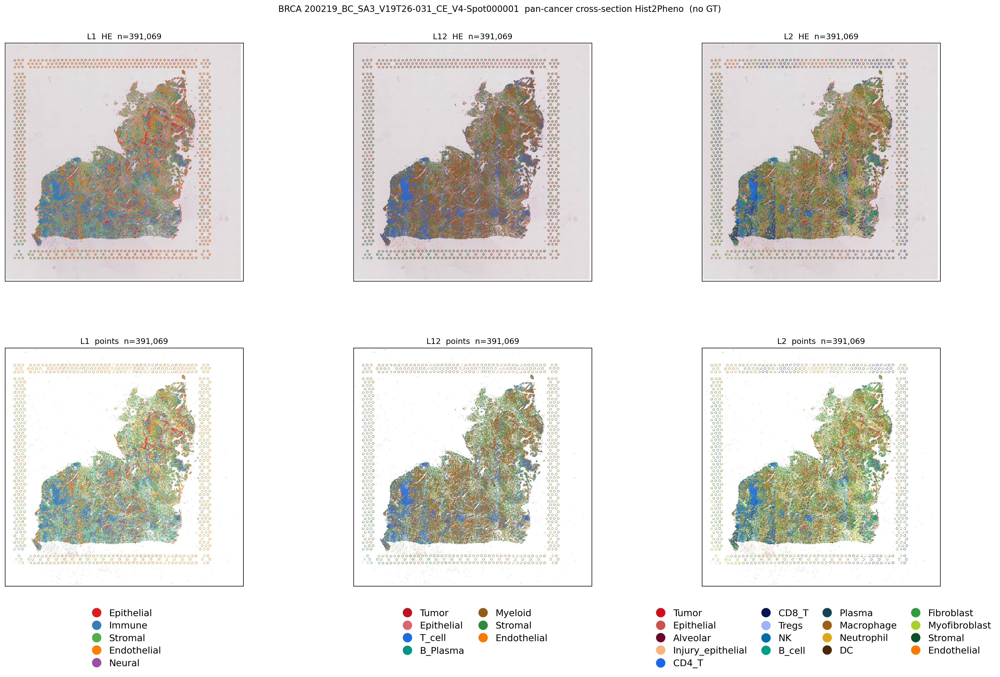

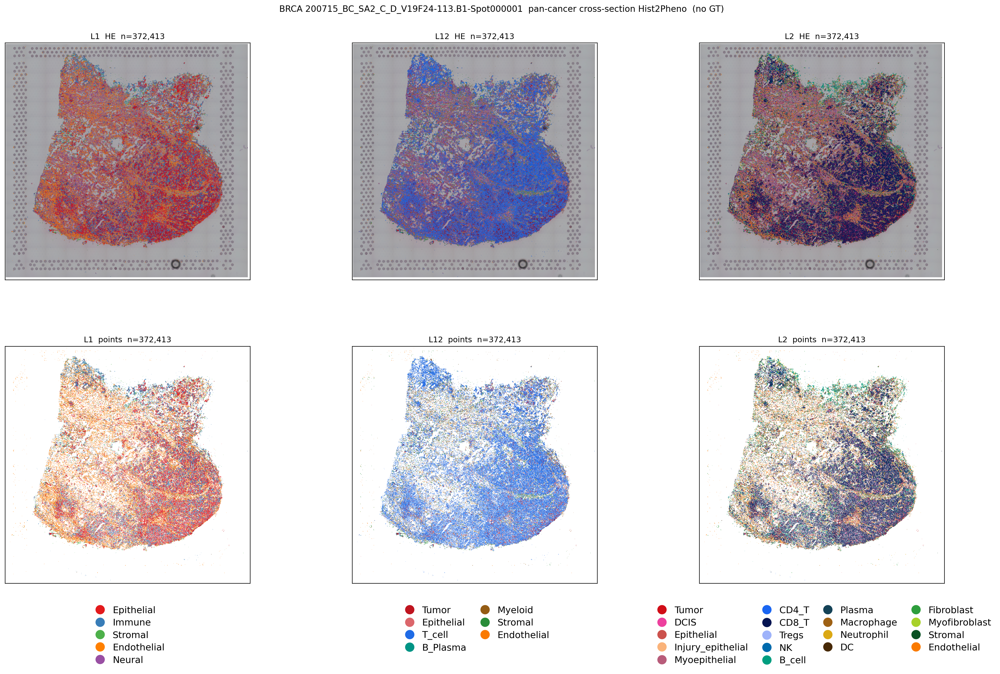

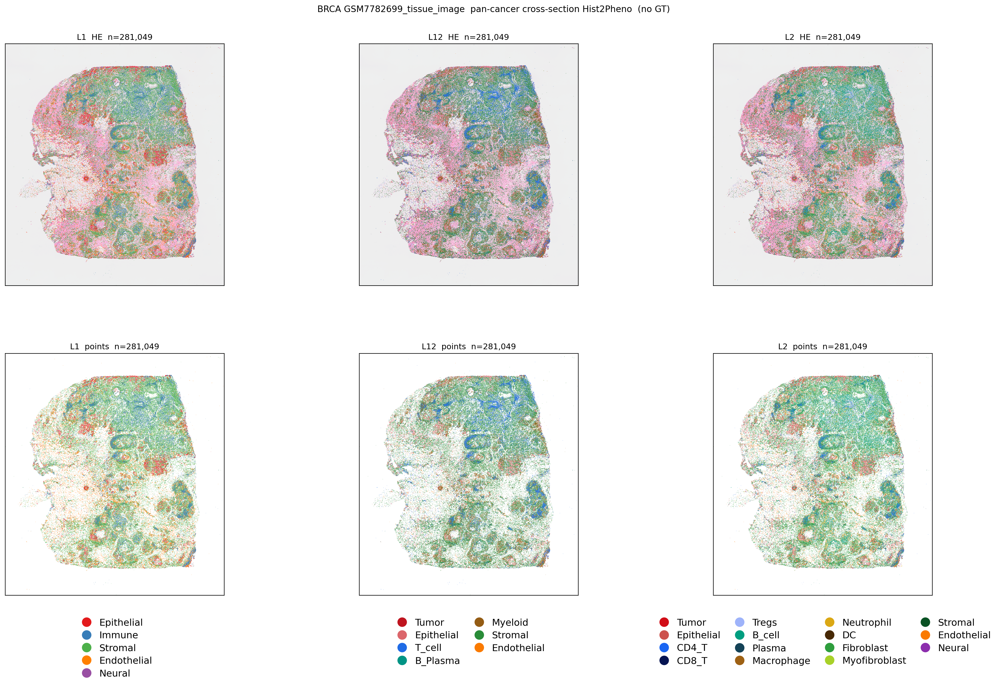

In [3]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


### Single section + QuPath ROI

Section: `200219_BC_SA3_V19T26-031_CE_V4-Spot000001`  
ROI: `data/Visium/BRCA/HE_images/selected_rectangle_coordinates.tsv` (native HE pixels).


[plot] 200219_BC_SA3_V19T26-031_CE_V4-Spot000001  nuclei=391,069  neighbor=23.8px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points


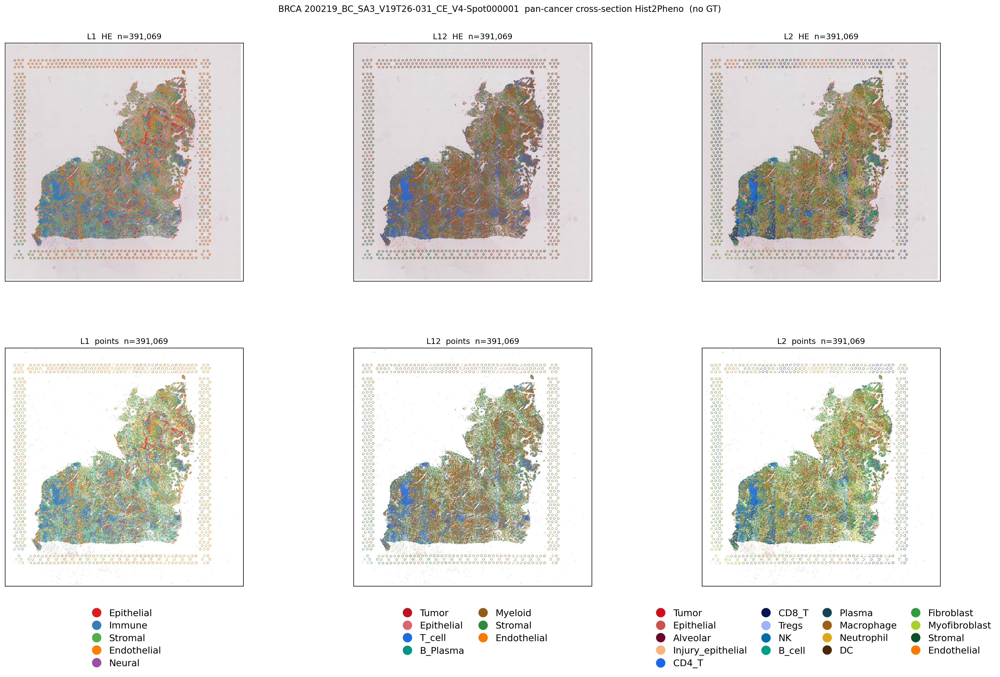

In [4]:
# One section only (full slide L1 / L12 / L2)
SAMPLE_ROI = "200219_BC_SA3_V19T26-031_CE_V4-Spot000001"
if SAMPLE_ROI not in samples:
    raise FileNotFoundError(
        f"{SAMPLE_ROI} not in discover_samples(): {samples}. "
        "Run: SAMPLE=... bash code/External_val/BRCA/demo.sh all"
    )
if not sample_paths(SAMPLE_ROI)["pred"].is_file():
    raise FileNotFoundError(sample_paths(SAMPLE_ROI)["pred"])

for fig in plot_spatial(
    [SAMPLE_ROI],
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


ROI 200219_BC_SA3_V19T26-031_CE_V4-Spot000001: x=[18296,20794] y=[39862,41783]  nuclei=2,595  MARKER_PX_ROI=5.0


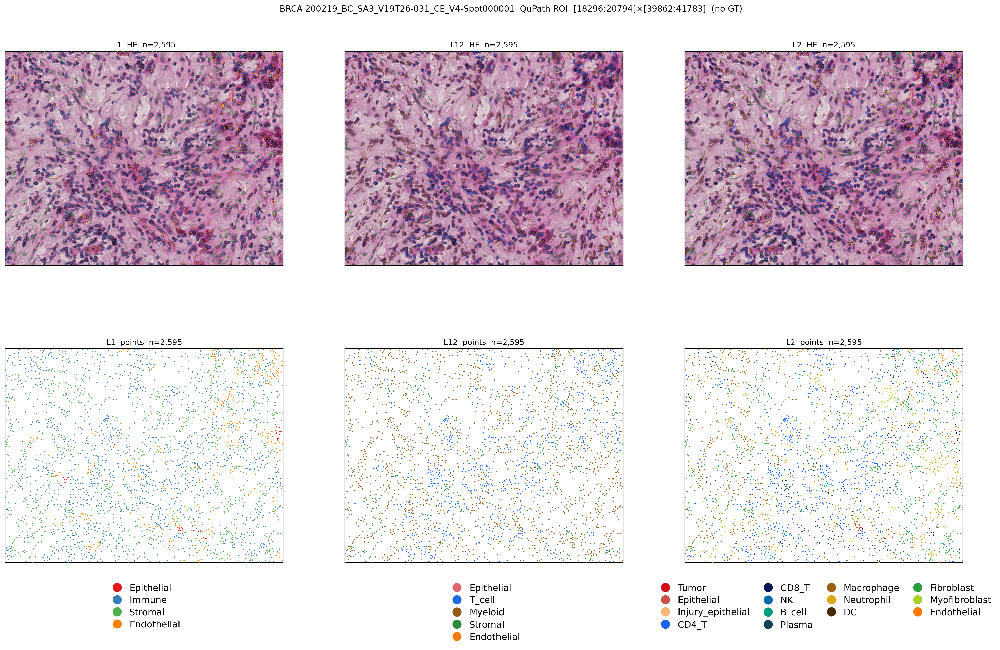

In [5]:
# ROI from QuPath rectangle → L1 / L12 / L2 on cropped HE
# Full-slide MARKER_PX (~1) is too small once the view is a ~2.5k×2k crop.
ROI_TSV = REPO / "data" / "Visium" / "BRCA" / "HE_images" / "selected_rectangle_coordinates.tsv"
MARKER_PX_ROI = max(float(MARKER_PX) * 5.0, 5.0)
fig_h = float(FIGSIZE[1]) * 1.9 if FIGSIZE[1] <= 8.5 else float(FIGSIZE[1])

fig, pred, in_roi, roi = plot_roi_spatial(
    SAMPLE_ROI,
    ROI_TSV,
    marker_px=MARKER_PX_ROI,
    dpi=DPI,
    figsize=(float(FIGSIZE[0]), fig_h),
    legend_markersize=13,
    legend_fontsize=13,
    title_fontsize=11,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
)
print(
    f"ROI {SAMPLE_ROI}: x=[{roi['x_min_px']:.0f},{roi['x_max_px']:.0f}] "
    f"y=[{roi['y_min_px']:.0f},{roi['y_max_px']:.0f}]  "
    f"nuclei={int(in_roi.sum()):,}  MARKER_PX_ROI={MARKER_PX_ROI:.1f}"
)
display(fig)
plt.close(fig)


head,L1,L12,L2
class,,,
B_cell,0.000,0.000,0.030
CD4_T,0.000,0.000,0.226
CD8_T,0.000,0.000,0.026
DC,0.000,0.000,0.000
Endothelial,0.126,0.000,0.044
Epithelial,0.013,0.001,0.001
Fibroblast,0.000,0.000,0.238
Immune,0.541,0.000,0.000
Injury_epithelial,0.000,0.000,0.002


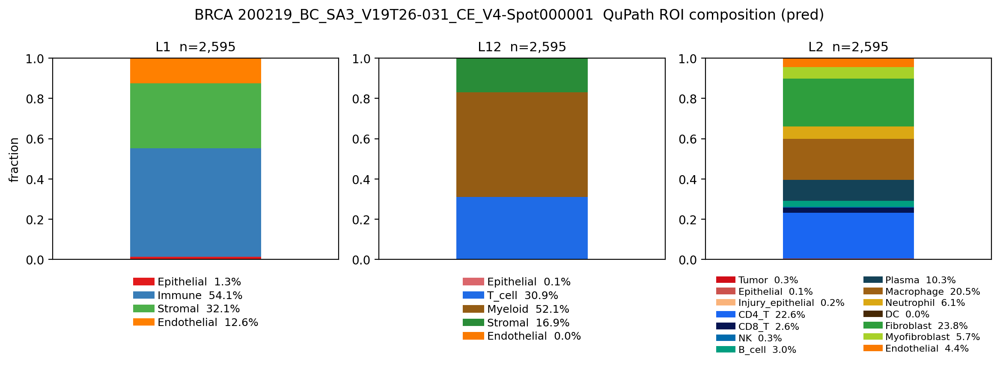

In [6]:
# ROI cell-type composition (100% stacked): L1 / L12 / L2
fig, comp_df = plot_roi_composition(
    SAMPLE_ROI,
    pred=pred,
    in_roi=in_roi,
    dpi=DPI,
    figsize=(12.0, 4.2),
    legend_fontsize_l1=9,
    legend_fontsize_l2=8,
    title_fontsize=11,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
)
display(comp_df.pivot_table(index="class", columns="head", values="fraction").fillna(0).round(3))
display(fig)
plt.close(fig)


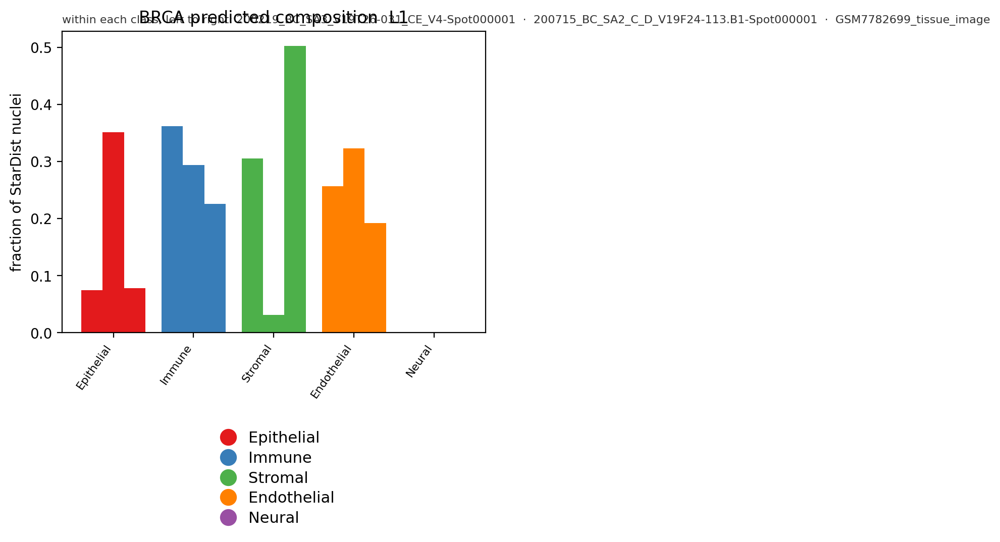

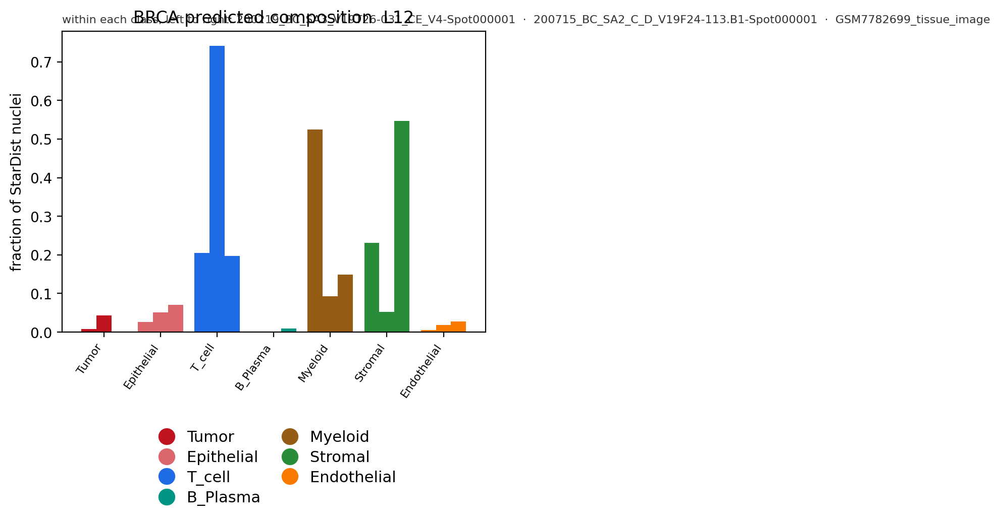

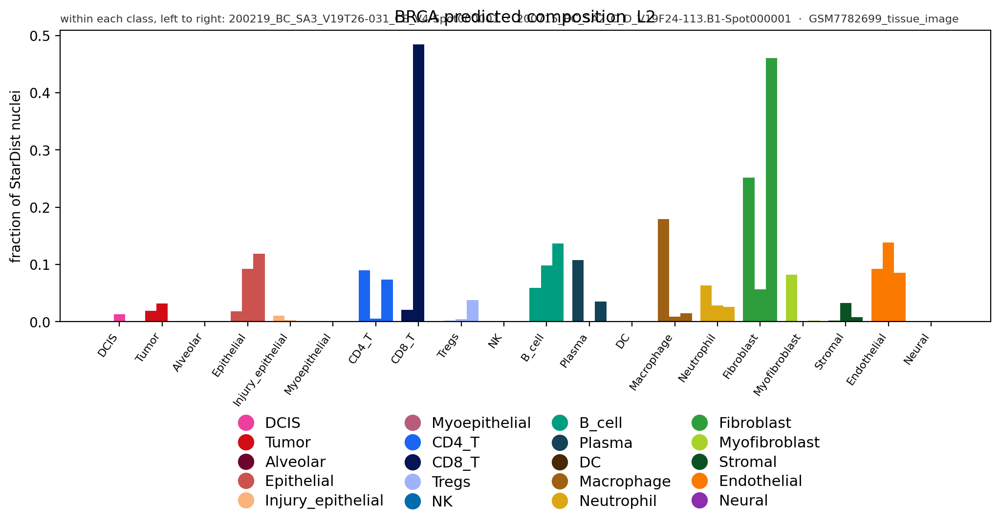

In [7]:
for fig in plot_composition(samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used: those members (AT1/AT2, activated fibrotic FBs, SPP1+ macrophages) are not pan-cancer L2 classes.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz` (first call reloads the cross-section checkpoint).

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS, as in the lung T-cell set. `spatial_HE` is native HE pixels, so R = **55 µm** is converted with **each sample's** `geometry(sample)['mpp_um']` (GSM ~0.548; Zenodo JPEGs ~0.172), not 0.5. Hotspots are the within-slide 95th percentile. TLS, SRI, and TNI each use a 1×3 row: abundance, the spatial score without markers, then the same spatial map with cyan candidate nuclei. The two spatial panels share one color scale.


In [5]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0  # lung notebook cross-dataset TLS radius
RECOMPUTE_NICHE = False

BRCA_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(samples[0])["mpp_um"]),  # formula table only; cell below uses per-sample mpp
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA",
)
print("µm/px by sample:", {s: round(float(geometry(s)["mpp_um"]), 4) for s in samples})
display(hni.index_formula_table(BRCA_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


In [6]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, BRCA_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

[niche] cache GSM7782699_tissue_image_niche_indices.h5ad  n=281,049  µm/px=0.5476
  TLS hotspot: {'n_cells_total': 281049, 'n_candidate_cells': 14053, 'fraction_candidate': 0.05000195695412544, 'max_tls_spatial': 0.18320576876630437, 'mean_tls_spatial_candidate': 0.1365601657778884, 'centroid_x': 12088.447874297912, 'centroid_y': 8169.324984349671}
  mean TLS=0.340  TLS_spatial=0.093  SRI=69.352  TNI=88.172


/home/lingyu/ssd2/Python/Hist2Pheno/data/Visium/BRCA/pred_pancancer_section/figures/tls_score_summary.csv


,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,GSM7782699_tissue_image,281049,0.34,0.303,0.668,0.988,0.093,0.091,0.127,0.183,0.569,0.546,0.233,0.378,0.12,0.588


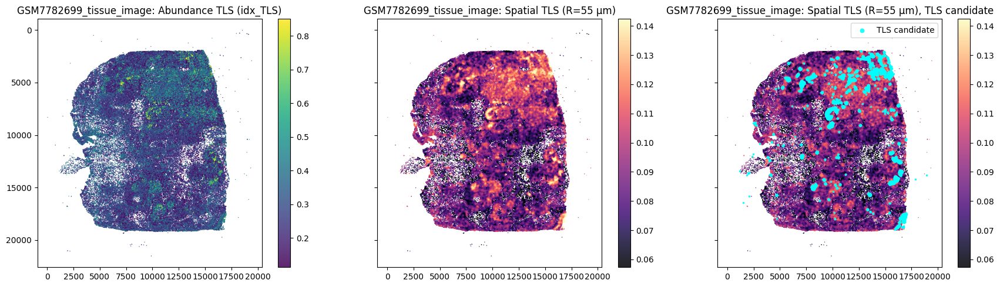

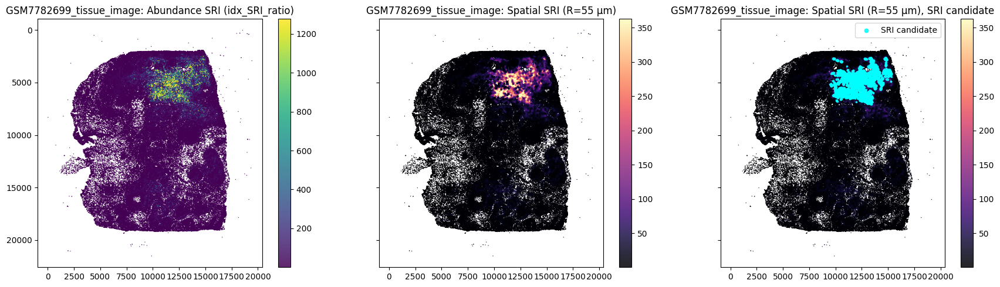

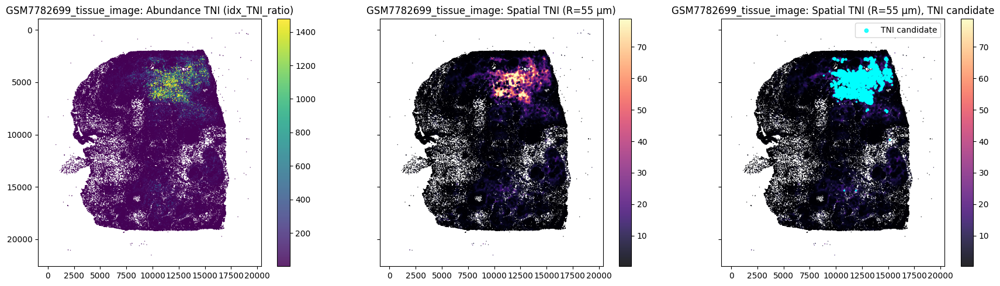

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)


def tls_score_row(df, sample: str) -> dict:
    """Quantify abundance TLS vs spatial TLS on the same nuclei."""
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }


quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
tls_quant = pd.DataFrame(quant_rows)
tls_quant_path = fig_dir / "tls_score_summary.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in niche_frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)

    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
